In [1]:
import os
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

print("Working directory:", os.getcwd())
print("Evaluation environment ready.")

Working directory: C:\Users\Chaithanya Reddy\Projects\Airguard\notebooks
Evaluation environment ready.


In [2]:
data_path = "../data/processed/vijayawada_features.csv"
model_path = "../models/airguard_xgboost_pm25.pkl"

print("Dataset exists:", os.path.exists(data_path))
print("Saved model exists:", os.path.exists(model_path))

Dataset exists: True
Saved model exists: True


In [3]:
# Load the processed dataset
df = pd.read_csv("../data/processed/vijayawada_features.csv")

# Load the saved XGBoost model and feature configuration
xgb_model = joblib.load("../models/airguard_xgboost_pm25.pkl")
feature_info = joblib.load("../models/airguard_feature_config.pkl")

feature_columns = feature_info["features"]
target_column = feature_info["target"]

# Convert timestamp and sort chronologically
df["collected_at"] = pd.to_datetime(df["collected_at"])
df = df.sort_values("collected_at").reset_index(drop=True)

# Reconstruct the chronological split
train_data = df[df["collected_at"] < "2024-02-01"].copy()

validation_data = df[
    (df["collected_at"] >= "2024-02-01") &
    (df["collected_at"] < "2024-03-01")
].copy()

test_data = df[
    (df["collected_at"] >= "2024-03-01") &
    (df["collected_at"] < "2024-04-01")
].copy()

# Prepare the test features and actual targets
X_test = test_data[feature_columns]
y_test = test_data[target_column]

print("Training rows:", len(train_data))
print("Validation rows:", len(validation_data))
print("Test rows:", len(test_data))
print("Number of features:", len(feature_columns))
print("Test date range:", test_data["collected_at"].min(),
      "to", test_data["collected_at"].max())

print("\nFeature columns:")
print(feature_columns)

print("\nTest feature shape:", X_test.shape)
print("Missing feature values:", X_test.isna().sum().sum())
print("Missing target values:", y_test.isna().sum())

Training rows: 1513
Validation rows: 1890
Test rows: 2397
Number of features: 23
Test date range: 2024-03-01 00:00:00 to 2024-03-31 22:00:00

Feature columns:
['PM2.5', 'PM10', 'NO2', 'SO2', 'CO', 'pm25_lag_1h', 'pm25_lag_2h', 'pm25_lag_3h', 'pm25_lag_6h', 'pm25_lag_12h', 'pm25_lag_24h', 'pm25_rolling_mean_3h', 'pm25_rolling_mean_6h', 'pm25_rolling_mean_12h', 'pm25_rolling_mean_24h', 'PM10_lag_1h', 'NO2_lag_1h', 'SO2_lag_1h', 'CO_lag_1h', 'hour', 'day_of_week', 'month', 'is_weekend']

Test feature shape: (2397, 23)
Missing feature values: 0
Missing target values: 0


In [4]:
# Generate XGBoost predictions
y_pred_xgb = xgb_model.predict(X_test)

# Persistence baseline: next-hour PM2.5 = current PM2.5
y_pred_persistence = test_data["PM2.5"].to_numpy()

# Calculate evaluation metrics
def evaluate_regression(y_true, y_pred, model_name):
    return {
        "Model": model_name,
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
        "R2": r2_score(y_true, y_pred)
    }

results = pd.DataFrame([
    evaluate_regression(y_test, y_pred_persistence, "Persistence"),
    evaluate_regression(y_test, y_pred_xgb, "XGBoost")
])

print(results.round(4).to_string(index=False))

      Model    MAE   RMSE     R2
Persistence 2.4732 4.1057 0.6500
    XGBoost 2.6720 3.9295 0.6794


In [5]:
# Create a diagnostic dataset
error_analysis = test_data[
    ["collected_at", "station_id", "PM2.5", target_column]
].copy()

error_analysis["prediction"] = y_pred_xgb

error_analysis["residual"] = (
    error_analysis[target_column]
    - error_analysis["prediction"]
)

error_analysis["absolute_error"] = (
    error_analysis["residual"].abs()
)

# Summary statistics
print("Residual summary:")
print(error_analysis["residual"].describe().round(3))

print("\nError thresholds:")
for threshold in [5, 10, 20]:
    count = (error_analysis["absolute_error"] > threshold).sum()
    percentage = count / len(error_analysis) * 100

    print(
        f"Absolute error > {threshold}: "
        f"{count} observations ({percentage:.2f}%)"
    )

print("\nLargest prediction errors:")
print(
    error_analysis.sort_values(
        "absolute_error", ascending=False
    )[
        [
            "collected_at",
            "station_id",
            "PM2.5",
            target_column,
            "prediction",
            "residual",
            "absolute_error"
        ]
    ].head(10).round(2).to_string(index=False)
)

Residual summary:
count    2397.000
mean        0.101
std         3.929
min       -25.228
25%        -1.909
50%         0.035
75%         1.956
max        33.619
Name: residual, dtype: float64

Error thresholds:
Absolute error > 5: 309 observations (12.89%)
Absolute error > 10: 57 observations (2.38%)
Absolute error > 20: 11 observations (0.46%)

Largest prediction errors:
       collected_at station_id  PM2.5  target_pm25  prediction  residual  absolute_error
2024-03-11 20:00:00  site_5981  43.95        73.24   39.619999     33.62           33.62
2024-03-05 20:00:00  site_5981  40.49        73.77   40.459999     33.31           33.31
2024-03-07 01:00:00  site_5981  35.47        67.57   35.779999     31.79           31.79
2024-03-02 05:00:00  site_5981  40.14        63.92   38.049999     25.87           25.87
2024-03-05 08:00:00  site_5848  90.98        42.02   67.250000    -25.23           25.23
2024-03-05 07:00:00  site_5848  71.78        90.98   66.680000     24.30           24.30
2

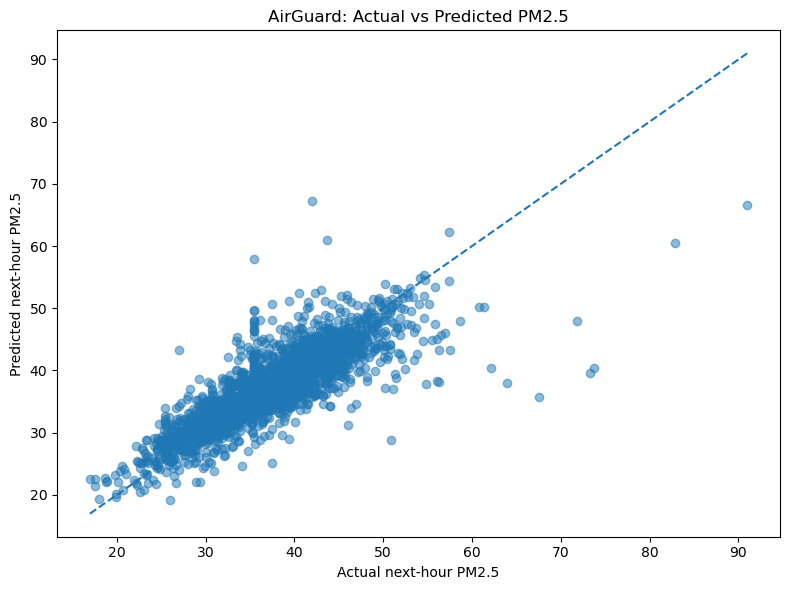

In [6]:
plt.figure(figsize=(8, 6))

plt.scatter(
    error_analysis["target_pm25"],
    error_analysis["prediction"],
    alpha=0.5
)

lower = min(
    error_analysis["target_pm25"].min(),
    error_analysis["prediction"].min()
)

upper = max(
    error_analysis["target_pm25"].max(),
    error_analysis["prediction"].max()
)

plt.plot(
    [lower, upper],
    [lower, upper],
    linestyle="--"
)

plt.xlabel("Actual next-hour PM2.5")
plt.ylabel("Predicted next-hour PM2.5")
plt.title("AirGuard: Actual vs Predicted PM2.5")
plt.tight_layout()
plt.show()

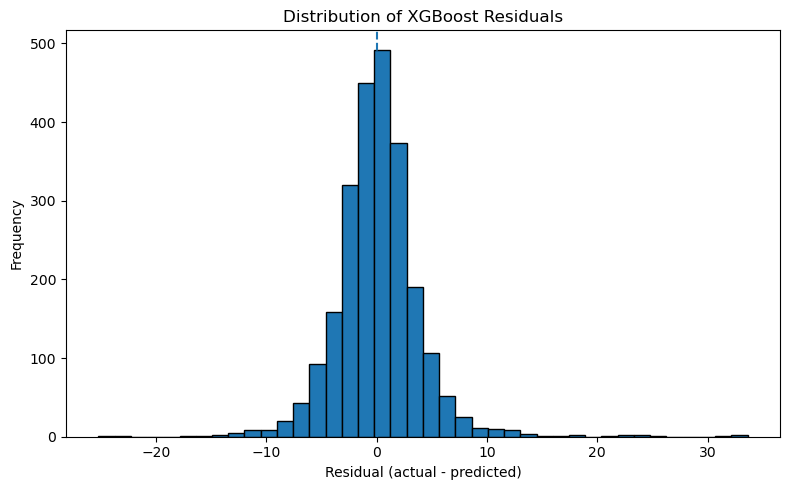

In [7]:
plt.figure(figsize=(8, 5))

plt.hist(
    error_analysis["residual"],
    bins=40,
    edgecolor="black"
)

plt.axvline(0, linestyle="--")

plt.xlabel("Residual (actual - predicted)")
plt.ylabel("Frequency")
plt.title("Distribution of XGBoost Residuals")
plt.tight_layout()
plt.show()

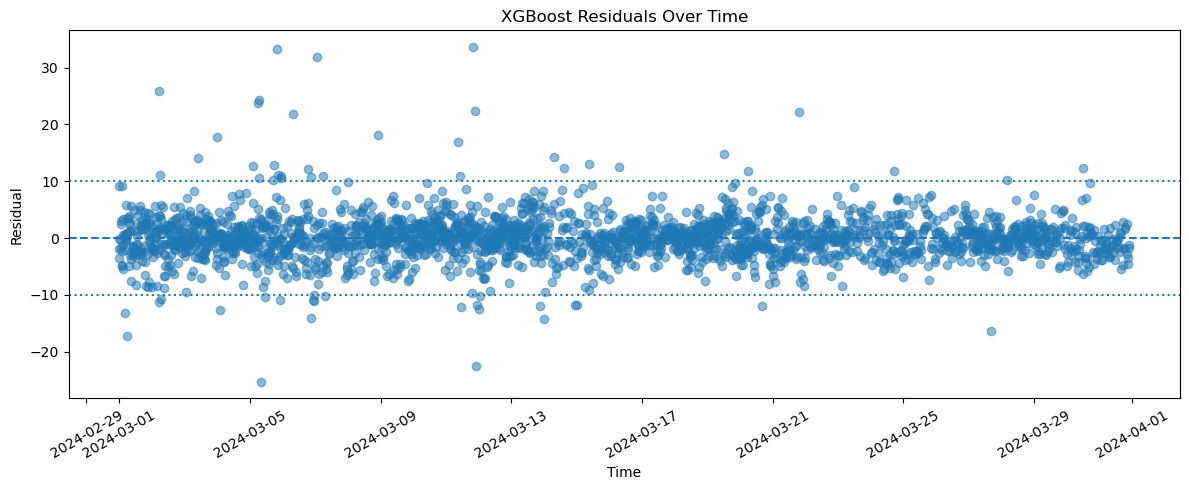

In [8]:
plt.figure(figsize=(12, 5))

plt.scatter(
    error_analysis["collected_at"],
    error_analysis["residual"],
    alpha=0.5
)

plt.axhline(0, linestyle="--")
plt.axhline(10, linestyle=":")
plt.axhline(-10, linestyle=":")

plt.xlabel("Time")
plt.ylabel("Residual")
plt.title("XGBoost Residuals Over Time")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

In [9]:
# Calculate metrics separately for each station
station_results = []

for station, group in error_analysis.groupby("station_id"):
    station_results.append({
        "Station": station,
        "Observations": len(group),
        "MAE": mean_absolute_error(
            group[target_column],
            group["prediction"]
        ),
        "RMSE": np.sqrt(mean_squared_error(
            group[target_column],
            group["prediction"]
        )),
        "R2": r2_score(
            group[target_column],
            group["prediction"]
        )
    })

station_results = pd.DataFrame(station_results)

print(station_results.round(3).to_string(index=False))

  Station  Observations   MAE  RMSE    R2
site_5685           463 1.739 2.299 0.813
site_5848           743 2.687 3.854 0.672
site_5849           714 2.969 3.799 0.675
site_5981           477 3.111 5.266 0.337


In [10]:
# Prepare chronological validation and training features
X_train = train_data[feature_columns]
y_train = train_data[target_column]

X_val = validation_data[feature_columns]
y_val = validation_data[target_column]

# Generate predictions
y_pred_train = xgb_model.predict(X_train)
y_pred_val = xgb_model.predict(X_val)
y_pred_test = xgb_model.predict(X_test)

def evaluate_split(name, y_true, y_pred):
    return {
        "Dataset": name,
        "Rows": len(y_true),
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
        "R2": r2_score(y_true, y_pred)
    }

split_results = pd.DataFrame([
    evaluate_split("Train", y_train, y_pred_train),
    evaluate_split("Validation", y_val, y_pred_val),
    evaluate_split("Test", y_test, y_pred_test)
])

print(split_results.round(4).to_string(index=False))

   Dataset  Rows    MAE    RMSE      R2
     Train  1513 1.5324  2.0910  0.9913
Validation  1890 9.6639 27.9605 -0.0382
      Test  2397 2.6720  3.9295  0.6794


In [11]:
baseline_results = pd.DataFrame([
    evaluate_split(
        "Train - Persistence",
        y_train,
        train_data["PM2.5"].to_numpy()
    ),
    evaluate_split(
        "Validation - Persistence",
        y_val,
        validation_data["PM2.5"].to_numpy()
    ),
    evaluate_split(
        "Test - Persistence",
        y_test,
        test_data["PM2.5"].to_numpy()
    )
])

print(baseline_results.round(4).to_string(index=False))

                 Dataset  Rows    MAE    RMSE     R2
     Train - Persistence  1513 4.9058 15.8981 0.4967
Validation - Persistence  1890 8.4503 26.0537 0.0986
      Test - Persistence  2397 2.4732  4.1057 0.6500


In [12]:
# Verify dataset sizes
assert len(train_data) == 1513
assert len(validation_data) == 1890
assert len(test_data) == 2397

# Verify feature and target completeness
assert X_test.shape == (2397, 23)
assert X_test.isna().sum().sum() == 0
assert y_test.isna().sum() == 0

# Verify prediction dimensions
assert len(y_pred_train) == len(y_train)
assert len(y_pred_val) == len(y_val)
assert len(y_pred_test) == len(y_test)

# Verify predictions are finite
assert np.isfinite(y_pred_train).all()
assert np.isfinite(y_pred_val).all()
assert np.isfinite(y_pred_test).all()

# Verify model metrics are finite
assert np.isfinite(
    split_results[["MAE", "RMSE", "R2"]].to_numpy()
).all()

print("PASS: Dataset sizes verified.")
print("PASS: No missing test features or targets.")
print("PASS: Prediction dimensions match actual targets.")
print("PASS: Predictions and metrics contain finite values.")
print("All evaluation checks passed.")

PASS: Dataset sizes verified.
PASS: No missing test features or targets.
PASS: Prediction dimensions match actual targets.
PASS: Predictions and metrics contain finite values.
All evaluation checks passed.


In [13]:
assert train_data["collected_at"].max() < validation_data["collected_at"].min()
assert validation_data["collected_at"].max() < test_data["collected_at"].min()

print("PASS: Training precedes validation.")
print("PASS: Validation precedes testing.")
print("PASS: Chronological split verified.")

PASS: Training precedes validation.
PASS: Validation precedes testing.
PASS: Chronological split verified.


In [14]:
from sklearn.model_selection import TimeSeriesSplit
from xgboost import XGBRegressor

# Use only January and February for cross-validation.
cv_data = df[
    df["collected_at"] < "2024-03-01"
].sort_values("collected_at").copy()

# Split unique timestamps, not individual rows.
unique_times = np.sort(cv_data["collected_at"].unique())

tscv = TimeSeriesSplit(n_splits=3)

cv_results = []

for fold, (train_idx, val_idx) in enumerate(
    tscv.split(unique_times), start=1
):
    train_times = unique_times[train_idx]
    val_times = unique_times[val_idx]

    fold_train = cv_data[
        cv_data["collected_at"].isin(train_times)
    ]

    fold_val = cv_data[
        cv_data["collected_at"].isin(val_times)
    ]

    X_fold_train = fold_train[feature_columns]
    y_fold_train = fold_train[target_column]

    X_fold_val = fold_val[feature_columns]
    y_fold_val = fold_val[target_column]

    # Same model configuration as the original XGBoost model.
    fold_model = XGBRegressor(
        n_estimators=200,
        max_depth=6,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        random_state=42,
        n_jobs=-1
    )

    fold_model.fit(X_fold_train, y_fold_train)
    fold_predictions = fold_model.predict(X_fold_val)

    cv_results.append({
        "Fold": fold,
        "Train_End": fold_train["collected_at"].max(),
        "Validation_Start": fold_val["collected_at"].min(),
        "Validation_End": fold_val["collected_at"].max(),
        "Train_Rows": len(fold_train),
        "Validation_Rows": len(fold_val),
        "MAE": mean_absolute_error(
            y_fold_val, fold_predictions
        ),
        "RMSE": np.sqrt(mean_squared_error(
            y_fold_val, fold_predictions
        )),
        "R2": r2_score(y_fold_val, fold_predictions)
    })

cv_results = pd.DataFrame(cv_results)

print(cv_results.round(4).to_string(index=False))

print("\nMean cross-validation metrics:")
print(
    cv_results[["MAE", "RMSE", "R2"]]
    .mean()
    .round(4)
)

 Fold           Train_End    Validation_Start      Validation_End  Train_Rows  Validation_Rows     MAE    RMSE     R2
    1 2024-01-16 17:00:00 2024-01-16 18:00:00 2024-01-31 11:00:00         763              728  5.3775  7.0685 0.5235
    2 2024-01-31 11:00:00 2024-01-31 12:00:00 2024-02-15 05:00:00        1491              925  7.9190 15.5966 0.4026
    3 2024-02-15 05:00:00 2024-02-15 06:00:00 2024-02-29 23:00:00        2416              987 10.0460 32.4788 0.0115

Mean cross-validation metrics:
MAE      7.7808
RMSE    18.3813
R2       0.3125
dtype: float64


In [15]:
import os

os.makedirs("../reports", exist_ok=True)

cv_results.to_csv(
    "../reports/week4_time_series_cv_results.csv",
    index=False
)

station_results.to_csv(
    "../reports/week4_station_metrics.csv",
    index=False
)

split_results.to_csv(
    "../reports/week4_split_metrics.csv",
    index=False
)

baseline_results.to_csv(
    "../reports/week4_persistence_metrics.csv",
    index=False
)

print("Saved Week 4 evaluation results:")
print("- week4_time_series_cv_results.csv")
print("- week4_station_metrics.csv")
print("- week4_split_metrics.csv")
print("- week4_persistence_metrics.csv")

Saved Week 4 evaluation results:
- week4_time_series_cv_results.csv
- week4_station_metrics.csv
- week4_split_metrics.csv
- week4_persistence_metrics.csv


In [16]:
import os

files_to_check = [
    "../reports/week4_time_series_cv_results.csv",
    "../reports/week4_station_metrics.csv",
    "../reports/week4_split_metrics.csv",
    "../reports/week4_persistence_metrics.csv"
]

for file in files_to_check:
    assert os.path.exists(file), f"Missing file: {file}"
    print("PASS:", file)

PASS: ../reports/week4_time_series_cv_results.csv
PASS: ../reports/week4_station_metrics.csv
PASS: ../reports/week4_split_metrics.csv
PASS: ../reports/week4_persistence_metrics.csv


In [17]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

# Synthetic example: 1 means a pollution alert is needed.
y_true_class = [1, 1, 1, 0, 0, 0, 1, 0]
y_pred_class = [1, 0, 1, 0, 1, 0, 1, 0]

print("Accuracy:", accuracy_score(y_true_class, y_pred_class))
print("Precision:", precision_score(y_true_class, y_pred_class))
print("Recall:", recall_score(y_true_class, y_pred_class))
print("F1-score:", f1_score(y_true_class, y_pred_class))

print("\nConfusion matrix:")
print(confusion_matrix(y_true_class, y_pred_class))

print("\nClassification report:")
print(classification_report(y_true_class, y_pred_class))

Accuracy: 0.75
Precision: 0.75
Recall: 0.75
F1-score: 0.75

Confusion matrix:
[[3 1]
 [1 3]]

Classification report:
              precision    recall  f1-score   support

           0       0.75      0.75      0.75         4
           1       0.75      0.75      0.75         4

    accuracy                           0.75         8
   macro avg       0.75      0.75      0.75         8
weighted avg       0.75      0.75      0.75         8



In [18]:
import os

files_to_check = [
    "../reports/week4_time_series_cv_results.csv",
    "../reports/week4_station_metrics.csv",
    "../reports/week4_split_metrics.csv",
    "../reports/week4_persistence_metrics.csv"
]

for file in files_to_check:
    if os.path.exists(file):
        print("PASS:", file)
    else:
        print("MISSING:", file)

PASS: ../reports/week4_time_series_cv_results.csv
PASS: ../reports/week4_station_metrics.csv
PASS: ../reports/week4_split_metrics.csv
PASS: ../reports/week4_persistence_metrics.csv
